# What pushes a Batman story up or down BatChat's list?

The previous notebook found that creator names and dates predict a little of BatChat's taste. This one asks the follow-up a fan actually cares about: **which names, which years, which characters?** And do the same things move Goodreads readers and RoundUp critics, or does the podcast have its own tells?

[BatChat](https://comicsxf.com/batchat-rankings/) is a podcast where Matt Lazorwitz and Will Nevin have ranked 740 Batman stories. **Rank 1 is best.** We fit one simple model per audience, then read off what it learned.

Prerequisite reading: [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) explains the model and why its predictions are modest. Companions: [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories)

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)*

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from sklearn.compose import make_column_transformer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
BLUE, ORANGE, GREY = "#2767A0", "#D57927", "#75818C"

stories = pd.read_csv(DATA / "stories.csv")
issues = pd.read_csv(DATA / "issues.csv")
N = len(stories)
# Higher = more liked, so coefficients read the same way for BatChat and the star ratings.
stories["batchat_score"] = N - stories["rank"]

/mnt/d/Research/data/Batchat/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The same model as before, in two lines

A linear model: every feature gets a weight, and a story's predicted score is the sum of its weights. Names and characters are yes/no columns (a name needs five stories to get one; three in the small outside-rating samples); year and issue count are scaled numbers. The weights **are** the answer to "what drives the ranking", so this notebook is mostly about reading them carefully.

In [2]:
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
NAMES = ["narrative_" + r for r in ROLES]
CAST = ["featured_entity_ids", "antagonists_entity_ids"]
WHEN = ["cover_year_start", "issue_count"]

X = stories[["medium", "format_hint", *WHEN, *NAMES, *CAST]].copy()
X[NAMES + CAST] = X[NAMES + CAST].fillna("")


def model(min_df=5):
    """Each |-separated name becomes a 0/1 column; a name needs `min_df` stories to count."""
    features = make_column_transformer(
        (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), WHEN),
        (OneHotEncoder(handle_unknown="ignore", min_frequency=min_df), ["medium", "format_hint"]),
        *[
            (
                CountVectorizer(
                    token_pattern=r"[^|]+", lowercase=False, binary=True, min_df=min_df
                ),
                col,
            )
            for col in NAMES + CAST
        ],
        verbose_feature_names_out=True,
    )
    return make_pipeline(features, RidgeCV(alphas=np.logspace(0, 4, 9)))


ROLE_OF = {f"countvectorizer-{i + 1}": col for i, col in enumerate(NAMES + CAST)}
ROLE_LABEL = {
    **{c: c.removeprefix("narrative_")[:-1] for c in NAMES},
    "featured_entity_ids": "featured",
    "antagonists_entity_ids": "antagonist",
}


def pretty(feature):
    """'countvectorizer-2__Frank Miller' -> 'Frank Miller (penciler)'; characters lose their universe label."""
    prefix, _, value = feature.partition("__")
    if prefix in ROLE_OF:
        return f"{value.split(' (')[0]} ({ROLE_LABEL[ROLE_OF[prefix]]})"
    if prefix == "onehotencoder":
        return value.replace("format_hint_", "format: ").replace("medium_", "medium: ")
    return {"cover_year_start": "cover year", "issue_count": "issue count"}.get(value, value)


def fit_weights(X, y):
    """Fit and return each feature's weight. Smaller samples get a lower name threshold."""
    fitted = model(min_df=max(3, len(X) // 150)).fit(X, y)
    weights = pd.Series(fitted[-1].coef_, index=fitted[0].get_feature_names_out()).rename(pretty)
    # A character can appear under two universe labels; merge them into one weight.
    return fitted, weights.groupby(level=0).sum()

## 1. BatChat: who and what moves a story up the list?

The twenty most positive and twenty most negative weights. A weight of +60 means: all else equal, this name is worth about 60 places higher on the list. Blue = helps, orange = hurts.

Two cautions before you read names. Each weight is *given everything else in the model*: Frank Miller's weight is what's left after the model has already credited Klaus Janson, Lynn Varley, and 1986. And a weight is a correlation inside the hosts' list, not a verdict on anyone's career.

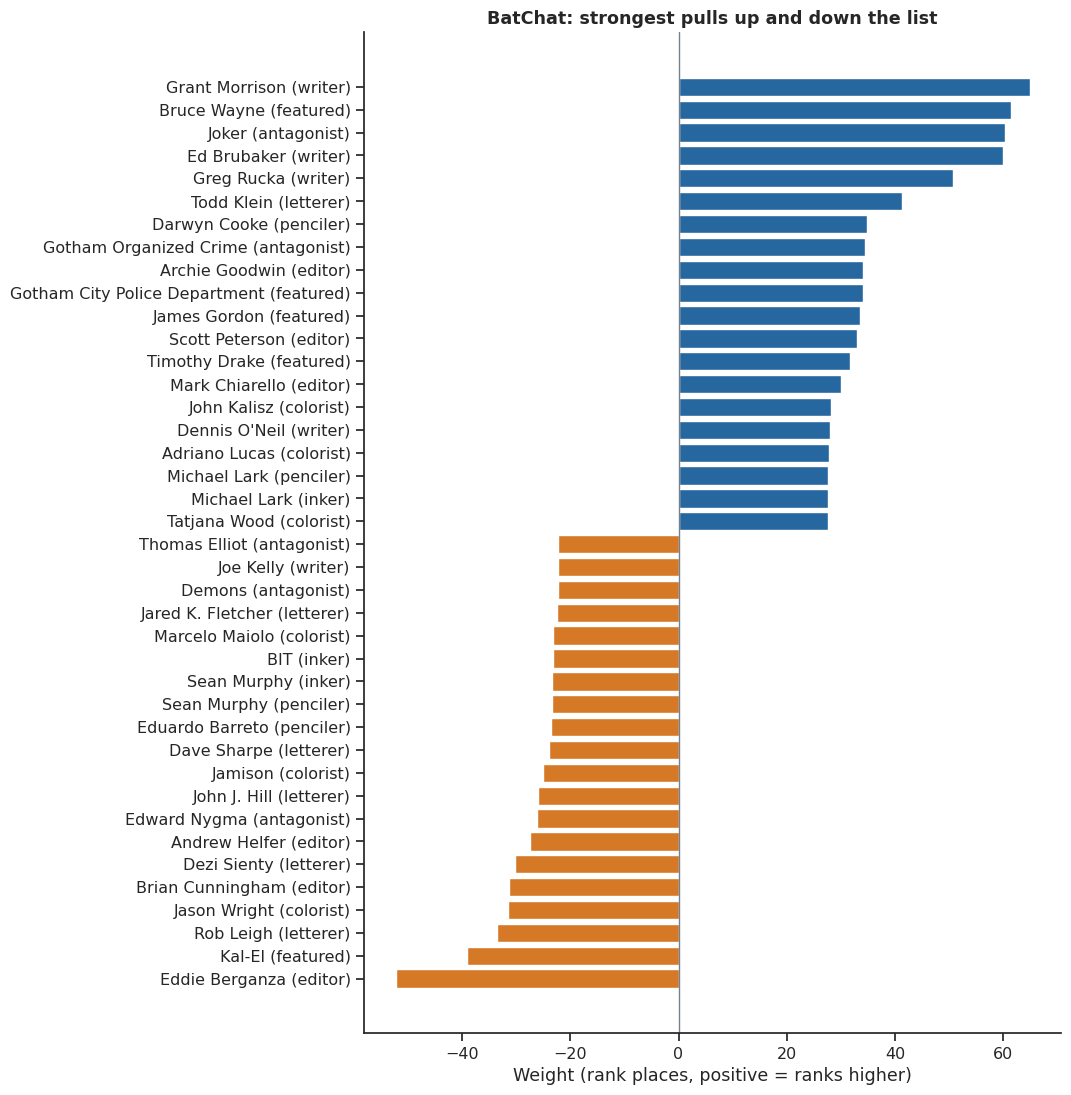

In [3]:
batchat_model, batchat_weights = fit_weights(X, stories.batchat_score)


def weight_plot(weights, title, n=20):
    top = pd.concat([weights.nlargest(n), weights.nsmallest(n)]).sort_values()
    fig, ax = plt.subplots(figsize=(9, 0.3 * len(top) + 1))
    ax.barh(top.index, top, color=np.where(top > 0, BLUE, ORANGE))
    ax.axvline(0, color=GREY, lw=1)
    ax.set(xlabel="Weight (rank places, positive = ranks higher)", title=title)
    plt.show()


weight_plot(batchat_weights, "BatChat: strongest pulls up and down the list")

**Darwyn Cooke** is the biggest single boost: about **+85 places**. Then Grant Morrison, Ed Brubaker, Michael Lark, Archie Goodwin, Greg Rucka, Matt Wagner. Note how many of the top twenty are not writers: Todd Klein and Klaus Janson, Dick Giordano, Mark Chiarello (an editor). Gotham Organized Crime and the GCPD as cast are worth about +35 each: the hosts like crime stories.

On the other side, editor **Eddie Berganza** is the strongest drag (about −50), then **Sean Murphy** and **Lee Bermejo**, then a run of 2010s–2020s artists (Jason Fabok, Mikel Janin, Rob Leigh). The pattern is less "bad creators" than "a particular era of DC the hosts don't rate": glossy, event-driven, post-New 52 Batman.

## 2. Are the big weights real, or noise?

Names appearing in five stories can get a large weight by luck. Two checks:

- **Shuffle test (permutation importance):** scramble one feature group at a time and see how much the held-out predictions worsen. Big loss = the group matters.
- **Stability:** refit on five different subsets and keep only names whose weight has the same sign every time.

Held-out error: 172 rank places


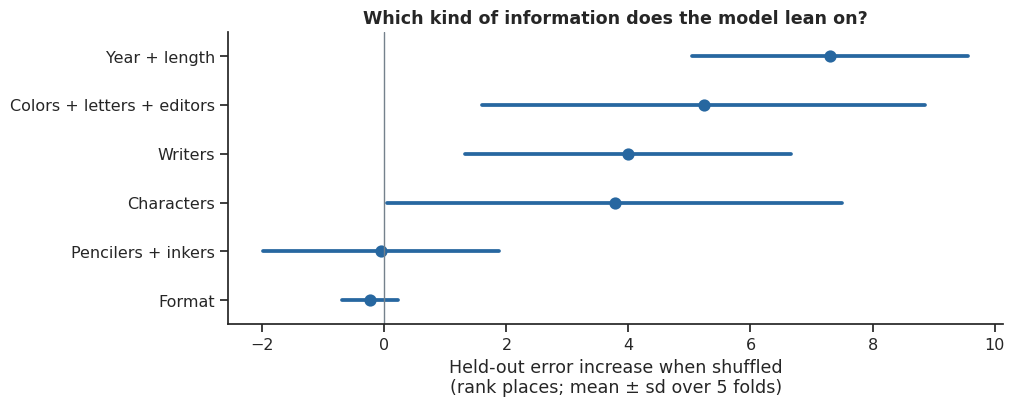

In [4]:
links = pd.concat(
    [
        pd.DataFrame({"story_id": stories.story_id, "key": "episode " + stories.episode_url}),
        pd.DataFrame(
            {"story_id": issues.story_id, "key": "issue " + issues.issue_id.astype("string")}
        ),
    ]
).dropna()
group_of = {}
for _, ids in links.groupby("key").story_id:
    root = min(group_of.get(i, i) for i in ids)
    for i in ids:
        group_of[i] = root
groups = stories.story_id.map(lambda s: group_of.get(s, s))
folds = list(GroupKFold(n_splits=5, shuffle=True, random_state=42).split(X, groups=groups))

held_out = cross_val_predict(model(), X, stories.batchat_score, cv=folds)
print(f"Held-out error: {np.abs(held_out - stories.batchat_score).mean():.0f} rank places")

blocks = {
    "Year + length": WHEN,
    "Format": ["medium", "format_hint"],
    "Writers": ["narrative_writers"],
    "Pencilers + inkers": ["narrative_pencilers", "narrative_inkers"],
    "Colors + letters + editors": [
        "narrative_colorists",
        "narrative_letterers",
        "narrative_editors",
    ],
    "Characters": CAST,
}
rows = []
for train, test in folds:
    fitted = model().fit(X.iloc[train], stories.batchat_score.iloc[train])
    base = np.abs(fitted.predict(X.iloc[test]) - stories.batchat_score.iloc[test]).mean()
    rng = np.random.default_rng(0)
    for block, cols in blocks.items():
        shuffled = X.iloc[test].copy()
        shuffled[cols] = shuffled[cols].sample(frac=1, random_state=rng.integers(1e6)).to_numpy()
        rows.append(
            {
                "block": block,
                "worse by": np.abs(
                    fitted.predict(shuffled) - stories.batchat_score.iloc[test]
                ).mean()
                - base,
            }
        )
importance = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 3.8))
sns.pointplot(
    data=importance,
    x="worse by",
    y="block",
    order=importance.groupby("block")["worse by"].mean().sort_values(ascending=False).index,
    errorbar="sd",
    linestyle="none",
    color=BLUE,
    ax=ax,
)
ax.axvline(0, color=GREY, lw=1)
ax.set(
    xlabel="Held-out error increase when shuffled\n(rank places; mean ± sd over 5 folds)",
    ylabel="",
    title="Which kind of information does the model lean on?",
)
plt.show()

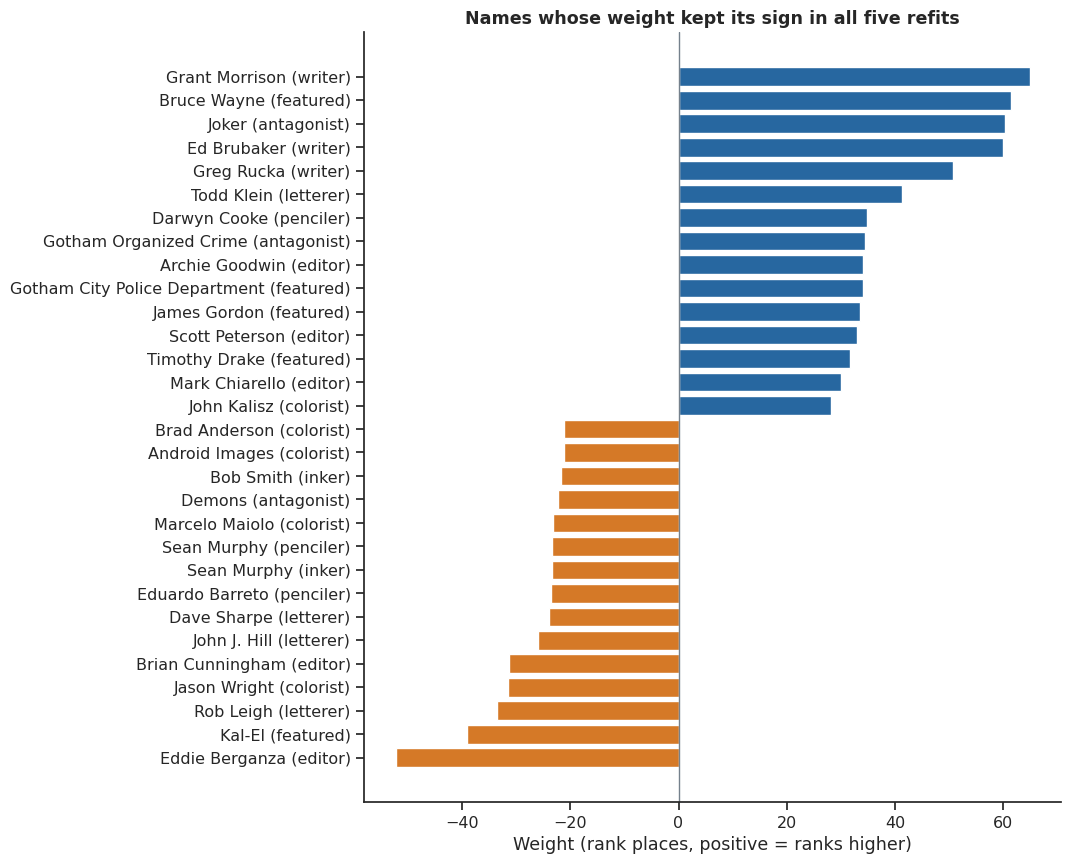

In [5]:
signs = pd.DataFrame(
    {
        k: fit_weights(X.iloc[train], stories.batchat_score.iloc[train])[1]
        for k, (train, _) in enumerate(folds)
    }
).fillna(0)
stable = signs[(np.sign(signs).nunique(axis=1) == 1) & (signs.abs().min(axis=1) > 10)]
stable_weights = batchat_weights[batchat_weights.index.isin(stable.index)]
weight_plot(stable_weights, "Names whose weight kept its sign in all five refits", n=15)

**Year and length matter most**, then the back-of-the-book credits (colorists, letterers, editors), then writers. Shuffling pencilers and inkers barely hurts, which is surprising for comics, until you remember a penciler mostly identifies an era the model already knows from the year. Format (comic vs graphic novel) adds nothing.

The stable list keeps most of the big names. Cooke, Morrison, Brubaker, Lark, Goodwin, Rucka survive five refits; so do Berganza, Murphy, Bermejo, and Fabok on the downside. Bane as an antagonist is a consistent small negative. These are the tells worth taking seriously.

## 3. Do readers and critics care about the same things?

Same features, same model, different target: Goodreads stars (40 matched books) and RoundUp reader and critic scores (110 and 78). These are small samples, so only the broad strokes count. Each panel shows the ten strongest weights, in that audience's own units.

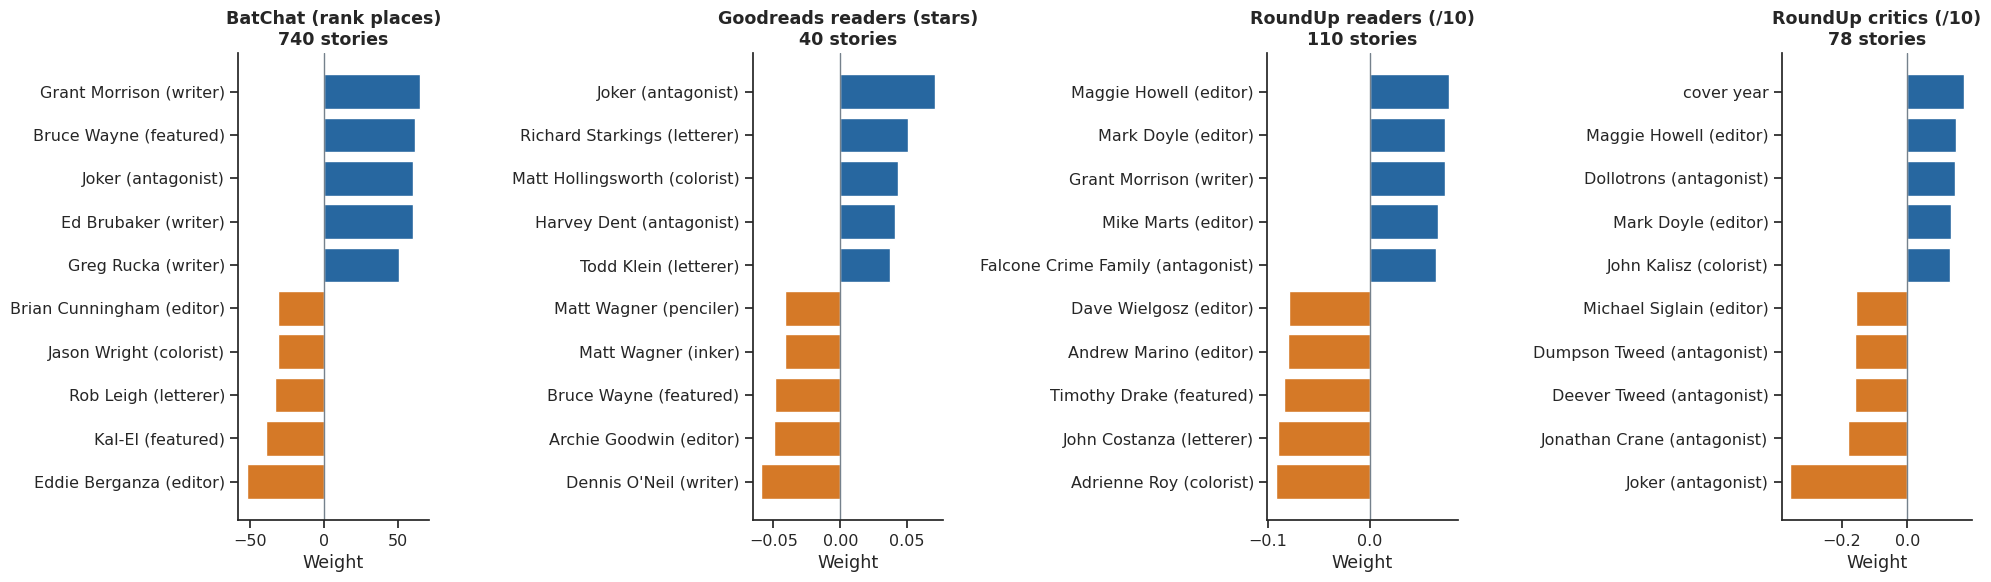

In [6]:
audiences = {
    "BatChat (rank places)": ("batchat_score", np.ones(N, dtype=bool)),
    "Goodreads readers (stars)": (
        "goodreads_rating",
        stories.goodreads_match_scope.eq("same_story") & stories.goodreads_rating_count.ge(100),
    ),
    "RoundUp readers (/10)": (
        "roundup_user_rating",
        stories.roundup_narrative_scope.eq("all_indexed_narratives")
        & stories.roundup_user_complete
        & stories.roundup_user_min_count.ge(5),
    ),
    "RoundUp critics (/10)": (
        "roundup_critic_rating",
        stories.roundup_narrative_scope.eq("all_indexed_narratives")
        & stories.roundup_critic_complete
        & stories.roundup_critic_min_count.ge(3),
    ),
}
audience_weights = {}
fig, axes = plt.subplots(1, 4, figsize=(20, 6))
for ax, (label, (target, ok)) in zip(axes, audiences.items()):
    _, w = fit_weights(X[ok], stories.loc[ok, target])
    audience_weights[label] = w
    top = pd.concat([w.nlargest(5), w.nsmallest(5)]).sort_values()
    ax.barh(top.index, top, color=np.where(top > 0, BLUE, ORANGE))
    ax.axvline(0, color=GREY, lw=1)
    ax.set(title=f"{label}\n{ok.sum()} stories", xlabel="Weight")
fig.tight_layout()
plt.show()

The audiences do not share tells. **Grant Morrison** is the only name that helps both BatChat and RoundUp readers. Goodreads readers reward the **Joker** and long collections; BatChat is indifferent to the Joker and penalizes long arcs. **Matt Wagner** is a plus for BatChat and the single biggest minus on Goodreads. Critics' top tell is **J.H. Williams III** and recency (`cover year`).

With 40–110 books per outside audience, individual names here are weak evidence. The broad read is solid though: BatChat's taste is built on creators from the 1980s–2000s, while Goodreads and critics lean on characters and recency.

## 4. The mismatches, explained feature by feature

For a linear model, [SHAP](https://shap.readthedocs.io/) values are exact: each feature's contribution is its weight times the story's value, and they sum to the prediction. So for any one story we can show *why* the model guessed what it did. Here are the three stories the hosts liked far more than the model, and the three they liked far less.

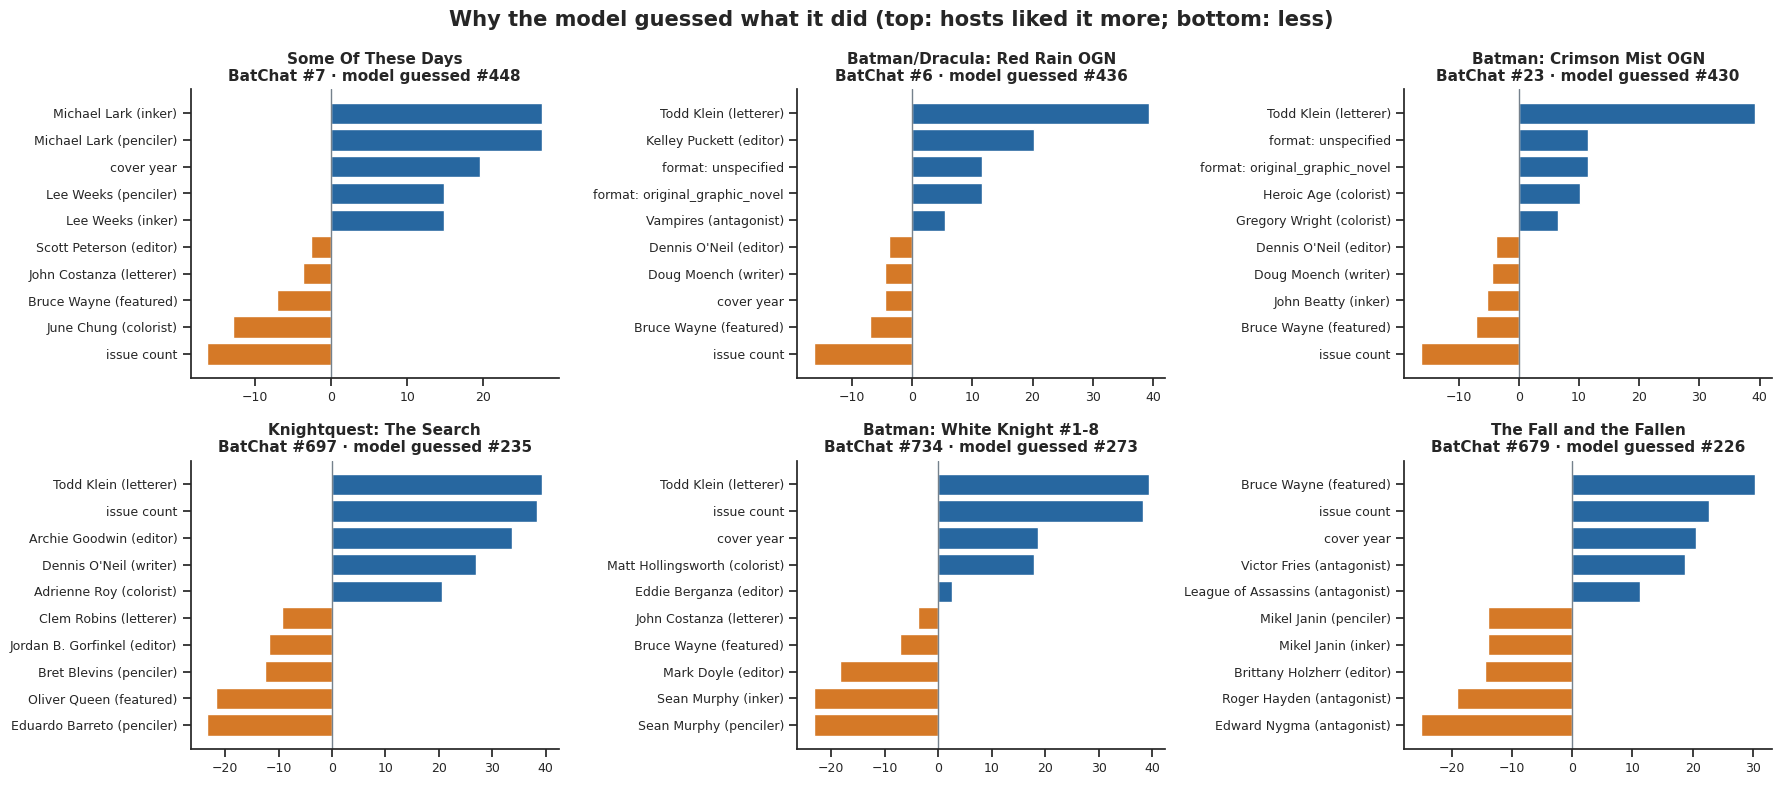

In [7]:
X_mat = batchat_model[0].transform(X)
X_mat = X_mat.toarray() if hasattr(X_mat, "toarray") else X_mat
explainer = shap.LinearExplainer(batchat_model[-1], X_mat)
contrib = pd.DataFrame(
    explainer.shap_values(X_mat),
    columns=batchat_model[0].get_feature_names_out(),
    index=stories.title,
)
contrib = contrib.rename(columns=pretty).T.groupby(level=0).sum().T
surprise = pd.Series(stories.batchat_score.to_numpy() - held_out, index=stories.title)
picks = list(surprise.nlargest(3).index) + list(surprise.nsmallest(3).index)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, title in zip(axes.flat, picks):
    parts = contrib.loc[title]
    parts = parts[parts != 0]
    top = pd.concat([parts.nlargest(5), parts.nsmallest(5)]).sort_values()
    ax.barh(top.index, top, color=np.where(top > 0, BLUE, ORANGE))
    ax.axvline(0, color=GREY, lw=1)
    rank = int(stories.loc[stories.title.eq(title), "rank"].iloc[0])
    guess = int(N - held_out[stories.title.eq(title)][0])
    ax.set_title(f"{title}\nBatChat #{rank} · model guessed #{guess}", fontsize=11)
    ax.tick_params(labelsize=9)
fig.suptitle(
    "Why the model guessed what it did (top: hosts liked it more; bottom: less)", fontweight="bold"
)
fig.tight_layout()
plt.show()

**The hosts' upside surprises are the model being blind to craft.** *Some of These Days* (#7) gets a boost from Michael Lark and Lee Weeks but is dragged by being a short one-issue story; the model has no idea it's a near-silent Elegy. *Red Rain* (#6) and *Crimson Mist* (#23) each get +40 from Todd Klein and lose on length, with Doug Moench a mild negative: the model has learned Moench's 1990s run averages poorly and can't see that the vampire trilogy is the exception.

**The downside surprises are era tells firing on books the hosts hated.** *White Knight* (#734) gets +40 from Todd Klein and +40 from being an eight-issue arc, while Sean Murphy's −45 is not enough. *Knightquest: The Search* (#697) is boosted by Archie Goodwin, Dennis O'Neil, and Adrienne Roy, the 1990s Bat-office the hosts usually like. *The Fall and the Fallen* (#679) is lifted by Bruce Wayne, Mr. Freeze, and a 2019 cover date, then pulled down by Bane and Mikel Janin.

## What we can and can't say

- **Yes, there are clear tells.** Darwyn Cooke, Grant Morrison, Ed Brubaker, Michael Lark, Greg Rucka, Archie Goodwin, and Todd Klein push a story up BatChat's list; Eddie Berganza, Sean Murphy, Lee Bermejo, and a cluster of 2010s artists pull it down. Crime-story casts (GCPD, Gotham's mobs) help.
- **The tells are era-shaped.** The single most useful fact is the cover year; most creator weights are shorthand for "which DC was this".
- **They are not the hosts' taste in full.** The model still misses by ~170 places. The biggest misses are books where craft, not credits, decided it: a silent issue, a gothic Elseworlds, a glossy modern arc.
- **Outside audiences run on different tells.** Only Grant Morrison helps everyone. Goodreads likes the Joker; BatChat doesn't care.

<details><summary>Methods notes</summary>

- **Model:** ridge regression with the penalty chosen by cross-validation; names and characters need at least five stories to get a column. Targets: BatChat score (740 − rank), Goodreads stars, RoundUp scores.
- **Why not SHAP for everything?** For a linear model SHAP values equal weight × value, so the weights chart *is* the global SHAP summary; we use `shap.LinearExplainer` only for per-story breakdowns. A tree model with TreeExplainer would show interactions, but the earlier notebook found the random forest no more accurate, so the simpler model is the honest one.
- **Permutation importance** shuffles whole feature groups on held-out folds (`sklearn.inspection.permutation_importance` does the same, one column at a time); groups keep correlated names together.
- **Stability** keeps a name only if its weight has the same sign and magnitude >10 in all five fold refits. This is a rough filter, not a significance test.
- All weights are associations within the 740 books the hosts chose. They describe this list, not the creators.

</details>

**More BatChat notebooks:** [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [Who gets the good Batman stories?](https://www.kaggle.com/code/danofer/who-gets-the-good-batman-stories) · [Gotham's rogues, ranked](https://www.kaggle.com/code/danofer/gotham-s-rogues-ranked) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)

If you enjoyed this, an upvote helps other Batman fans find it.